### Yt [Video](https://www.youtube.com/watch?v=jkfk6WASIeI&t=967s) Link for the class 


#### Week 1 - Pandas for Data Manipulation , Preprocessing , Standardization and Visualization
- fill up missing values in the dataset using mean, median, or mode as suitable.
- normalize the dataset using min-max normalization or z-score normalization so that models dont get baised for some features and ignore others.
- for categorical features,  use one-hot encoding or label encoding to convert them into numerical format.
-  Encoding -> defination : process of converting categorical data into numerical format so that machine learning algorithms can understand and process it effectively.
- This steps are **preprocessing and standardization of the dataset**. This is important because machine learning algorithms work best when the data is clean, consistent, and in a format that they can understand. By filling up missing values, normalizing the dataset, and encoding categorical features, we can ensure that our models are able to learn from the data effectively and make accurate predictions. 

In [667]:
import numpy as np 
import pandas as pd

#### Pandas Series

A Pandas Series is like a column in a table. It is a 1-D array holding data of any type.

A Pandas Series is a one-dimensional labeled array capable of storing elements of the same or different data types. Each element is associated with an index (label).


series Sturucture : [ [ index ] -> [ value ] ]

In [668]:
# creating a pandas series from a list

marks = [90, 85, 78, 92, 88]

marks_series = pd.Series(marks)

marks_series


0    90
1    85
2    78
3    92
4    88
dtype: int64

In [669]:
## gets defaults integer labels as index for the series. The index starts from 0 and goes up to n-1, where n is the number of elements in the series.

## for custom index, we can pass a list of labels to the index parameter of the Series constructor.

marks_series_custom_index = pd.Series(marks, index=['A', 'B', 'C', 'D', 'E'])
marks_series_custom_index

A    90
B    85
C    78
D    92
E    88
dtype: int64

In [670]:
# also can mention the data type (conversion if possible and error if not proper series values are passed) of the series using the dtype parameter of the Series constructor.
marks_series_with_dtype = pd.Series(marks, index=['A', 'B', 'C', 'D', 'E'], dtype=float)
marks_series_with_dtype

A    90.0
B    85.0
C    78.0
D    92.0
E    88.0
dtype: float64

In [671]:
# wrong_series = pd.Series([1, 2, 'three', 4], dtype='Int32')  # This will raise an error because 'three' cannot be converted to int

In [672]:
# series with help of dictionary. 
marks_dict = {'A': 85, 'B': 92, 'C': 78, 'D': 96, 'E': 88}
marks_series_from_dict = pd.Series(marks_dict)
print("--- Series from dictionary ---")
marks_series_from_dict

--- Series from dictionary ---


A    85
B    92
C    78
D    96
E    88
dtype: int64

#### what are DataFrames ?
- **DataFrames** are a two-dimensional, size-mutable, and heterogeneous data structure commonly used in data analysis and manipulation. They are similar to spreadsheets or SQL tables, where data is organized in rows and columns. Each column can hold different types of data (e.g., integers, strings, floats), and each row represents a single record or observation. 
- Each Row/column is a Series object, which is a one-dimensional labeled array capable of holding any data type. 

In [673]:
# creating dataframe from dictionary.

data = {
    "names" : ["Alice", "Bob", "Charlie", "David", "Eva"],
    "age" : [25, 30, 35, 40, 45],
    "city" : ["New York", "Los Angeles", "Chicago", "Houston", "Phoenix"], 
    "marks" : [85, 92, 78, 96, 88] , 
    "BMI" : [22.5, 24.0, 23.5, 25.0, 26.0]
}


student_df = pd.DataFrame(data)

print("--- DataFrame from list of lists ---")
student_df

--- DataFrame from list of lists ---


,names,age,city,marks,BMI
0,Alice,25,New York,85,22.5
1,Bob,30,Los Angeles,92,24.0
2,Charlie,35,Chicago,78,23.5
3,David,40,Houston,96,25.0
4,Eva,45,Phoenix,88,26.0


In [674]:
# creating dataframe from list of lists.

data = [
    ["Alice", 25, "New York", 85, 22.5],
    ["Bob", 30, "Los Angeles", 92, 24.0],
    ["Charlie", 35, "Chicago", 78, 23.5],
    ["David", 40, "Houston", 96, 25.0],
    ["Eva", 45, "Phoenix", 88, 26.0]
]

student_df_from_list = pd.DataFrame(data, columns=["names", "age", "city", "marks", "BMI"])

print("--- DataFrame from list of lists ---")
student_df_from_list

--- DataFrame from list of lists ---


,names,age,city,marks,BMI
0,Alice,25,New York,85,22.5
1,Bob,30,Los Angeles,92,24.0
2,Charlie,35,Chicago,78,23.5
3,David,40,Houston,96,25.0
4,Eva,45,Phoenix,88,26.0


In [675]:
# creating data from form differnt Series.

name_se = pd.Series(["Alice", "Bob", "Charlie", "David", "Eva"] , index=["name_0", "name_1", "name_2", "name_3", "name_4"])
age_se = pd.Series([25, 30, 35, 40, 45] , index=["age_0", "age_1", "age_2", "age_3", "age_4"])
city_se = pd.Series(["New York", "Los Angeles", "Chicago", "Houston", "Phoenix"] , index=["city_0", "city_1", "city_2", "city_3", "city_4"])
marks_se = pd.Series([85, 92, 78, 96, 88] , index=["Physics", "Chemistry", "Biology", "Mathematics", "English"])
BMI_se = pd.Series([22.5, 24.0, 23.5, 25.0, 26.0] , index=["BMI_0", "BMI_1", "BMI_2", "BMI_3", "BMI_4"])

# Printing the series to check the values and indexes.
print("--- Series ---")
print("Name Series:")
print(name_se)
print("\nAge Series:")
print(age_se)
print("\nCity Series:")
print(city_se)
print("\nMarks Series:")
print(marks_se)
print("\nBMI Series:")
print(BMI_se)


# df_student_from_series = pd.DataFrame({
#     "names": name_se,
#     "age": age_se,
#     "city": city_se,
#     "marks": marks_se,
#     "BMI": BMI_se
# })

## worng way to create dataframe from series as the indexes are different for each series.

# Each Series has different index labels:

#         name_se: name_0, name_1, ...
#         age_se: age_0, age_1, ...
#         city_se: city_0, city_1, ...
#         marks_se: Physics, Chemistry, ...
#         BMI_se: BMI_0, BMI_1, ...

# When pandas creates a DataFrame from Series, it matches values using their index labels, not their positions. Since the labels do not match, pandas creates separate rows and fills missing values with NaN.

## solution : 
## Use the same index for every Series:

        # student_index = ["student_0", "student_1", "student_2", "student_3", "student_4"]

        # name_se = pd.Series(["Alice", "Bob", "Charlie", "David", "Eva"], index=student_index)
        # age_se = pd.Series([25, 30, 35, 40, 45], index=student_index)
        # city_se = pd.Series(["New York", "Los Angeles", "Chicago", "Houston", "Phoenix"], index=student_index)
        # marks_se = pd.Series([85, 92, 78, 96, 88], index=student_index)
        # BMI_se = pd.Series([22.5, 24.0, 23.5, 25.0, 26.0], index=student_index)

        # df_student_from_series = pd.DataFrame({
        #     "names": name_se,
        #     "age": age_se,
        #     "city": city_se,
        #     "marks": marks_se,
        #     "BMI": BMI_se
        # })

        # df_student_from_series
        
## or use reset index to reset the index of each series before creating the DataFrame:

df_student_from_series = pd.DataFrame({
    "names": name_se.reset_index(drop=True),
    "age": age_se.reset_index(drop=True),
    "city": city_se.reset_index(drop=True),
    "marks": marks_se.reset_index(drop=True),
    "BMI": BMI_se.reset_index(drop=True)
})



#1. name_se.reset_index() ## Without it, drop defaults to False, so pandas tries to keep the old labels as a separate column.

# produces:
            #     index        0
            # 0   name_0    Alice
            # 1   name_1      Bob
            # 2   name_2  Charlie
            # 3   name_3    David
            # 4   name_4      Eva


#2. name_se.reset_index(drop=True)

# produces:
                # 0      Alice
                # 1        Bob
                # 2    Charlie
                # 3      David
                # 4        Eva
                # dtype: object
    
    
# All Series temporarily become indexed from 0 to 4

# names:  0, 1, 2, 3, 4
# age:    0, 1, 2, 3, 4
# city:   0, 1, 2, 3, 4
# marks:  0, 1, 2, 3, 4
# BMI:    0, 1, 2, 3, 4

# Therefore, pandas matches the values correctly using these common indexes:

# index 0 → Alice, 25, New York, 85, 22.5
# index 1 → Bob, 30, Los Angeles, 92, 24.0

--- Series ---
Name Series:
name_0      Alice
name_1        Bob
name_2    Charlie
name_3      David
name_4        Eva
dtype: object

Age Series:
age_0    25
age_1    30
age_2    35
age_3    40
age_4    45
dtype: int64

City Series:
city_0       New York
city_1    Los Angeles
city_2        Chicago
city_3        Houston
city_4        Phoenix
dtype: object

Marks Series:
Physics        85
Chemistry      92
Biology        78
Mathematics    96
English        88
dtype: int64

BMI Series:
BMI_0    22.5
BMI_1    24.0
BMI_2    23.5
BMI_3    25.0
BMI_4    26.0
dtype: float64


In [676]:
print("--- DataFrame from Series ---")
df_student_from_series

--- DataFrame from Series ---


,names,age,city,marks,BMI
0,Alice,25,New York,85,22.5
1,Bob,30,Los Angeles,92,24.0
2,Charlie,35,Chicago,78,23.5
3,David,40,Houston,96,25.0
4,Eva,45,Phoenix,88,26.0


##### Basic Info about DataFrames columns and some stats of numerical columns can be obtained using the `info()` and `describe()` methods of the DataFrame.

In [677]:
df_student_from_series.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   names   5 non-null      object 
 1   age     5 non-null      int64  
 2   city    5 non-null      object 
 3   marks   5 non-null      int64  
 4   BMI     5 non-null      float64
dtypes: float64(1), int64(2), object(2)
memory usage: 332.0+ bytes


In [678]:
df_student_from_series.describe()

,age,marks,BMI
count,5.000000,5.000000,5.000000
mean,35.000000,87.800000,24.200000
std,7.905694,6.870226,1.350926
min,25.000000,78.000000,22.500000
25%,30.000000,85.000000,23.500000
50%,35.000000,88.000000,24.000000
75%,40.000000,92.000000,25.000000
max,45.000000,96.000000,26.000000


In [679]:
## custom percentiles can be specified using the `percentiles` parameter of the `describe()` method. For example, to get the 10th, 25th, 50th, 75th, and 90th percentiles, you can use:

df_student_from_series.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])

,age,marks,BMI
count,5.000000,5.000000,5.000000
mean,35.000000,87.800000,24.200000
std,7.905694,6.870226,1.350926
min,25.000000,78.000000,22.500000
10%,27.000000,80.800000,22.900000
25%,30.000000,85.000000,23.500000
50%,35.000000,88.000000,24.000000
75%,40.000000,92.000000,25.000000
90%,43.000000,94.400000,25.600000
max,45.000000,96.000000,26.000000


#### Shape of the DataFrame/Series can be obtained using the `shape` attribute, which returns a tuple representing the number of rows and columns in the DataFrame.

In [680]:
df_student_from_series.shape

(5, 5)

In [681]:
name_se.shape

(5,)

#### Sample of data form top / bottom or at random from DataFrame/series can be obtained using the `head()`, `tail()`, and `sample()` methods of the DataFrame/Series.

In [682]:
name_se.head(2)

name_0    Alice
name_1      Bob
dtype: object

In [683]:
name_se.tail(2)

name_3    David
name_4      Eva
dtype: object

In [684]:
name_se.sample()

name_1    Bob
dtype: object

In [685]:
name_se.sample()

name_4    Eva
dtype: object

In [686]:
name_se.sample(random_state=11)

name_2    Charlie
dtype: object

In [687]:
name_se.sample(random_state=11)

name_2    Charlie
dtype: object

In [688]:
df_student_from_series.head(2) ## default  5 values 

,names,age,city,marks,BMI
0,Alice,25,New York,85,22.5
1,Bob,30,Los Angeles,92,24.0


In [689]:
df_student_from_series.tail(3)

,names,age,city,marks,BMI
2,Charlie,35,Chicago,78,23.5
3,David,40,Houston,96,25.0
4,Eva,45,Phoenix,88,26.0


In [690]:
df_student_from_series.sample()

,names,age,city,marks,BMI
4,Eva,45,Phoenix,88,26.0


#### Some Series methods/attributes are 
- `names`: Returns the name of the Series.
- `index`: Returns the index (labels) of the Series.
- `values`: Returns the values of the Series as a NumPy array.
- `dtype`: Returns the data type of the Series.
- `unique()`: Returns an array of unique values.
- `nunique()`: Returns the number of unique values.
- `is_unique` : Returns True if all values in the Series are unique, False otherwise.
- `value_counts()`: Returns a Series containing counts of unique values.
- `sort_values()`: Sorts the Series by its values.
- `sort_index()`: Sorts the Series by its index.
- `drop_duplicates()`: Removes duplicate values from the Series.
- `duplicated()`: Returns a boolean Series indicating which values are duplicated.
- `isnull()`: Returns a boolean Series indicating which values are null.
- `notnull()`: Returns a boolean Series indicating which values are not null.
- `fillna()`: Fills missing values with a specified value or method.
- `dropna()`: Drops rows with missing values.

In [691]:
name_se.value_counts()

Alice      1
Bob        1
Charlie    1
David      1
Eva        1
Name: count, dtype: int64

In [692]:
name_se.nunique()

5

In [693]:
marks_se.sort_values(ascending=False)

Mathematics    96
Chemistry      92
English        88
Physics        85
Biology        78
dtype: int64

In [694]:
marks_se.sort_index(ascending=True)

Biology        78
Chemistry      92
English        88
Mathematics    96
Physics        85
dtype: int64

##### Some Maths methods for Series are
- `sum()`: Returns the sum of the values in the Series.
-  `mean()`: Returns the mean (average) of the values in the Series.
- `median()`: Returns the median of the values in the Series.
- `mode()`: Returns the mode(s) of the values in the Series.
- `std()`: Returns the standard deviation of the values in the Series.
- `var()`: Returns the variance of the values in the Series.
- `min()`: Returns the minimum value in the Series.
- `max()`: Returns the maximum value in the Series.
- `quantile()`: Returns the value at a specified quantile of the Series.

In [695]:
print("--- Some Maths methods for Series ---")
print("sum of marks_se: ", marks_se.sum())
print("mean of marks_se: ", marks_se.mean())
print("median of marks_se: ", marks_se.median())
print("mode of marks_se: ", marks_se.mode())
print("standard deviation of marks_se: ", marks_se.std())
print("variance of marks_se: ", marks_se.var())
print("minimum value of marks_se: ", marks_se.min())
print("maximum value of marks_se: ", marks_se.max())
print("quantile of marks_se: ", marks_se.quantile(0.25))

--- Some Maths methods for Series ---
sum of marks_se:  439
mean of marks_se:  87.8
median of marks_se:  88.0
mode of marks_se:  0    78
1    85
2    88
3    92
4    96
dtype: int64
standard deviation of marks_se:  6.870225614927067
variance of marks_se:  47.199999999999996
minimum value of marks_se:  78
maximum value of marks_se:  96
quantile of marks_se:  85.0


##### Iteration on series can be done using the `items()` python method, which returns an iterator yielding pairs of index and value for each element in the Series. This allows you to loop through the Series and access both the index and the corresponding value.

In [696]:
for (index, value) in marks_se.items():
    print(f"Index: {index}, Value: {value}")
    

Index: Physics, Value: 85
Index: Chemistry, Value: 92
Index: Biology, Value: 78
Index: Mathematics, Value: 96
Index: English, Value: 88


#### Series Indexing 
-  it is important to note that the indexing behavior of a Pandas Series has changed in recent versions. In older versions, using square brackets `[]` with an integer key would treat it as a positional index. However, in newer versions, integer keys are treated as labels (index values) by default. This change was made to align the behavior of Series with that of DataFrames.
    - **dataframe[1] = returns a series of that column labeled as "1" not the second column of the dataframe.**


##### Suppose you have:

```
marks_series = pd.Series([90, 85, 78], index=[10, 20, 30])

print(marks_series)

```

Output:

| Index | Marks |
|---|---:|
| 10 | 90 |
| 20 | 85 |
| 30 | 78 |
dtype: int64

Now, if you do:

```
marks_series[1]
```

What does 1 mean?

Old pandas behavior

Pandas would interpret 1 as the position (second element), so you'd get:

85
New pandas behavior

Pandas wants Series to behave like DataFrames:

Integer keys are treated as labels, not positions.
Since there is no label 1 in the index [10, 20, 30], eventually this will raise a KeyError.

Therefore pandas gives this warning:

FutureWarning: Series.**getitem** treating keys as positions is deprecated.
Correct ways
Access by position

Use .iloc[] --> Integer position-based (starts at 0)

```
marks_series.iloc[1]

```

Output:

85

Here, 1 means "second element".

Access by label

Use .loc[] --> Label-based (index label)

```
marks_series.loc[20]

```

Output:

85

Here, 20 is the index label.

Why this change?

Pandas wants consistency:

For a DataFrame:

df[1]

means column label 1, not the second column.

Similarly, for a Series:

ser[1]

will mean label 1, not the second element.

**Rule to remember**

- nth element (position) ser.iloc[n]
- element with label x ser.loc[x]
- Avoid ambiguity Don't use ser[n]

#### Syntax for indexing and slicing in new syntax we use `.iloc[]` for position-based indexing and `.loc[]` for label-based indexing. This ensures clarity and avoids ambiguity in accessing elements of a Series or DataFrame.

##### synatax for `.iloc[]` and `.loc[]` is as follows for the series :

```
1. series.iloc[start:stop:step]  # position-based indexing

2. series.loc[start_label:stop_label:step]  # label-based indexing
```

In [697]:
marks_se.iloc[1]  ## position based indexing

92

In [698]:
marks_se.iloc[2:4]  # slicing 

Biology        78
Mathematics    96
dtype: int64

In [699]:
marks_series.iloc[-3::2]   # negative indexing and step slicing. This will return every second element starting from the third-to-last element to the end of the series.

2    78
4    88
dtype: int64

In [700]:
# fancy indexing :  is used when we dont able to make any pattern we directly poass list of row number to `.iloc[]` or row labels to `.loc[]` to get the required rows of the series.

marks_se.iloc[[0, 1, 4]]  # fancy indexing using .iloc[] with a list of positions

Physics      85
Chemistry    92
English      88
dtype: int64

In [701]:
marks_se.loc[["Physics" , "Chemistry"]]  # fancy indexing using .loc[] with a list of labels

Physics      85
Chemistry    92
dtype: int64

#### Series Editing 

In [702]:
marks_se

Physics        85
Chemistry      92
Biology        78
Mathematics    96
English        88
dtype: int64

In [703]:
## editing biology marks to 100 using  loc

marks_se.loc["Biology"] = 100

marks_se 

Physics         85
Chemistry       92
Biology        100
Mathematics     96
English         88
dtype: int64

In [704]:
## editing biology marks to 90 using iloc

marks_se.iloc[2] = 90

marks_se

Physics        85
Chemistry      92
Biology        90
Mathematics    96
English        88
dtype: int64

In [705]:
## fancy indexing for editing

name_se.loc["name_3"] = "Anish"

name_se

name_0      Alice
name_1        Bob
name_2    Charlie
name_3      Anish
name_4        Eva
dtype: object

#### Arithmetic and relational operations on Series  - are performed element-wise, meaning that the operation is applied to each corresponding element in the Series. This allows for efficient and concise manipulation of data.

- Arithmetic operations include `+`, `-`, `*`, `/`, and `**`. For example, if you have two Series of the same length, you can add them together to create a new Series where each element is the sum of the corresponding elements from the original Series. or you can 2 to any series to add 2 to each element of the series by the concept of broadcasting from numpy. Similarly, you can perform other arithmetic operations like subtraction, multiplication, and division in an element-wise manner.

- Relational operations include comparisons such as greater than, less than, equal to, etc. When you perform a relational operation between two Series of the same length, it returns a new Series of boolean values indicating the result of the comparison for each corresponding element. For example, if you compare two Series using the greater than operator (`>`), you'll get a Series where each element is `True` if the corresponding element in the first Series is greater than that in the second Series, and `False` otherwise.
or can just simply compare to a single value that will compare each element of the series to that value and return a boolean series by concept of broadcasting from numpy.

##### Examples of arithmetic operations on series are shown below.

In [706]:
marks_se

Physics        85
Chemistry      92
Biology        90
Mathematics    96
English        88
dtype: int64

In [707]:
age_se

age_0    25
age_1    30
age_2    35
age_3    40
age_4    45
dtype: int64

In [708]:
mark_add_age = marks_se.reset_index(drop=True) + age_se.reset_index(drop=True)
mark_add_age

## .reset_index(drop=True) needed as the index labels of marks_se and age_se are different, so we reset the index to align them before performing the addition.

0    110
1    122
2    125
3    136
4    133
dtype: int64

In [709]:
marks_se + 1000  # BroadCasiting 

Physics        1085
Chemistry      1092
Biology        1090
Mathematics    1096
English        1088
dtype: int64

##### Examples of Relational operations on series are shown below.

In [710]:
marks_se.reset_index(drop = True) >= age_se.reset_index(drop = True)

0    True
1    True
2    True
3    True
4    True
dtype: bool

In [711]:
marks_se < 90

Physics         True
Chemistry      False
Biology        False
Mathematics    False
English         True
dtype: bool

#### Boolean Indexing for the series using loc and iloc can be used to filter the series based on certain conditions. For example, you can use boolean indexing to select elements that meet a specific criterion, such as values greater than a certain threshold or values that are equal to a specific value. This allows for efficient data manipulation and analysis within the Pandas framework.

In [712]:
subs = pd.read_csv("./subs.csv").squeeze() ## holds data of subcribres per day for a 365 days of a yt channel.
subs.head()

0    48
1    57
2    40
3    43
4    44
Name: Subscribers gained Per Day, dtype: int64

In [713]:
# total number of days when sub of greater than tha mode 

val = subs.mode().values[0]  ## verify the mode  ((( subs.value_counts(ascending=False).head(1).index[0]  ))) 

print("Mode value of subscribers per day :", val)


subs[subs>val]

Mode value of subscribers per day : 105


35     123
36     108
37     110
45     126
46     109
      ... 
360    231
361    226
362    155
363    144
364    172
Name: Subscribers gained Per Day, Length: 221, dtype: int64

#### More Towards DataFrame 

A DataFrame is a two-dimensional table containing rows and columns.

- Rows have an index.
- Columns have labels.
- Each column is a Series.
- DataFrames can contain different data types in different columns.

In [714]:
# Create a DataFrame

student_df = pd.DataFrame({
    "name": ["Alice", "Bob", "Charlie", "David", "Eva" , "Frank", "Grace", "Hannah", "Ian", "Jack"],
    "age": [25, 30, 35, 40, 45 , 28, 32, 38, 42, 29],
    "city": ["New York", "Los Angeles", "Chicago", "Houston", "Phoenix" , "Philadelphia", "San Antonio", "San Diego", "Dallas", "San Jose"],
    "marks": [85, 92, 78, 96, 88 , 90, 95, 80, 85, 92]
})

student_df

,name,age,city,marks
0,Alice,25,New York,85
1,Bob,30,Los Angeles,92
2,Charlie,35,Chicago,78
3,David,40,Houston,96
4,Eva,45,Phoenix,88
5,Frank,28,Philadelphia,90
6,Grace,32,San Antonio,95
7,Hannah,38,San Diego,80
8,Ian,42,Dallas,85
9,Jack,29,San Jose,92


#### Important DataFrame Attributes

- `shape`: number of rows and columns.
- `size`: total number of elements.
- `columns`: column labels.
- `index`: row labels.
- `dtypes`: data type of each column.
- `values`: values as a NumPy array.

In [715]:
print("Shape of the DataFrame:", student_df.shape)
print("Size of the DataFrame:", student_df.size)
print("Columns of the DataFrame:", student_df.columns)
print("Index of the DataFrame:", student_df.index)
print("Data types of the DataFrame:", student_df.dtypes)

Shape of the DataFrame: (10, 4)
Size of the DataFrame: 40
Columns of the DataFrame: Index(['name', 'age', 'city', 'marks'], dtype='object')
Index of the DataFrame: RangeIndex(start=0, stop=10, step=1)
Data types of the DataFrame: name     object
age       int64
city     object
marks     int64
dtype: object


#### Basic DataFrame Methods

- `head(n)`: first `n` rows.
- `tail(n)`: last `n` rows.
- `sample(n)`: random rows.
- `info()`: structure and missing values.
- `describe()`: statistics of numerical columns.
- `value_counts()`: frequency of values in a column.

In [716]:
student_df.head(2)


,name,age,city,marks
0,Alice,25,New York,85
1,Bob,30,Los Angeles,92


In [717]:
student_df.tail(2)


,name,age,city,marks
8,Ian,42,Dallas,85
9,Jack,29,San Jose,92


In [718]:
student_df.sample(n=2, random_state=10)



,name,age,city,marks
8,Ian,42,Dallas,85
2,Charlie,35,Chicago,78


In [719]:
student_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   name    10 non-null     object
 1   age     10 non-null     int64 
 2   city    10 non-null     object
 3   marks   10 non-null     int64 
dtypes: int64(2), object(2)
memory usage: 452.0+ bytes


In [720]:
student_df.describe()


,age,marks
count,10.00000,10.000000
mean,34.40000,88.100000
std,6.65332,6.063552
min,25.00000,78.000000
25%,29.25000,85.000000
50%,33.50000,89.000000
75%,39.50000,92.000000
max,45.00000,96.000000


In [721]:
student_df["city"].value_counts()

city
New York        1
Los Angeles     1
Chicago         1
Houston         1
Phoenix         1
Philadelphia    1
San Antonio     1
San Diego       1
Dallas          1
San Jose        1
Name: count, dtype: int64

#### Selecting Columns

The `[]` syntax is commonly used to select columns.

- `df["column"]` returns a Series.
- `df[["column"]]` returns a DataFrame.
- `df[["column1", "column2"]]` selects multiple columns.

In [722]:
# One column: returns a Series
student_df["name"].head(2)



0    Alice
1      Bob
Name: name, dtype: object

In [723]:
# Multiple columns: returns a DataFrame
student_df[["name", "marks"]].head(2)



,name,marks
0,Alice,85
1,Bob,92


In [724]:
# Attribute notation works, but is not always recommended
student_df.marks.head(3)

0    85
1    92
2    78
Name: marks, dtype: int64

#### DataFrame Indexing

### `loc`

`loc` performs label-based selection.

Syntax:

`df.loc[row_labels, column_labels]`

### `iloc`

`iloc` performs position-based selection.

Syntax:

`df.iloc[row_positions, column_positions]`

Use `loc` when using labels and `iloc` when using row or column positions.

In [725]:
# loc: label-based indexing

student_df.loc[0] # returns the first row of the DataFrame as a Series, with the index labels corresponding to the column names.


name        Alice
age            25
city     New York
marks          85
Name: 0, dtype: object

In [726]:
student_df.loc[0, "name"] # returns the value in the "name" column of the first row of the DataFrame.


'Alice'

In [727]:
student_df.loc[0:2, ["name", "marks"]] # returns the first three rows of the DataFrame, with the "name" and "marks" columns.



,name,marks
0,Alice,85
1,Bob,92
2,Charlie,78


In [728]:
# iloc: position-based indexing

student_df.iloc[0]
student_df.iloc[0, 0]
student_df.iloc[0:3, [0, 3]]

,name,marks
0,Alice,85
1,Bob,92
2,Charlie,78


#### Difference Between `[]`, `loc`, and `iloc`

- `df["marks"]`: selects a column.
- `df[["name", "marks"]]`: selects multiple columns.
- `df.loc[0]`: selects the row having label `0`.
- `df.iloc[0]`: selects the first row by position.
- `df.loc[0, "marks"]`: selects using row and column labels.**Here row lable is int zero and column label is string "marks"**
- `df.iloc[0, 3]`: selects using row and column positions. **Here row position is 0 and column position is 3**

For clear and reliable row selection, prefer `loc` or `iloc`.

## Filtering DataFrames

Boolean filtering selects rows based on a condition.

Syntax : 

```
df[boolean series] ==  will return the rows where the boolean series is True as a new DataFrame.
```

In [729]:
# Students with marks greater than 85
student_df[student_df["marks"] > 85]

# Students aged 30 or above
student_df.loc[student_df["age"] >= 30]

# Select only required columns after filtering
student_df.loc[
    student_df["marks"] > 90,
    ["name", "marks"]
]




,name,marks
1,Bob,92
3,David,96
6,Grace,95
9,Jack,92


In [730]:

            # student_df.loc[
            #     student_df["marks"] > 90,
            #     ["name", "marks"]
            # ]
            
## the equivalent of the above code using [] notaion will be :

student_df[student_df["marks"] > 90][["name", "marks"]]

,name,marks
1,Bob,92
3,David,96
6,Grace,95
9,Jack,92


## Multiple Filtering Conditions

Use:

- `&` for AND
- `|` for OR
- `~` for NOT

Each condition must be written inside parentheses. as it might act weiredly as the bitwise operators have higher precedence than comparison operators. and soo on.


Create variable called for conditons : `cond_masks = (student_df["marks"] > 90) & (student_df["marks"] < 95)` which will return a boolean series of True and False values based on the condition. This boolean series can then be used to filter the DataFrame to select only the rows that meet the specified criteria.

In [731]:
# find the sutdents name and city whose age is bte 30 to 40 and marks is greater than 85

age_mask  = student_df["age"].between(30, 40)  # This will return a boolean series indicating whether each student's age is between 30 and 40 (inclusive).  or (student_df["age"] >= 30) & (student_df["age"] <= 40)\
marks_mask = student_df["marks"] > 85  # This will return a boolean series indicating whether each student's marks are greater than 85.

mask = (age_mask) & (marks_mask)
mask
student_df.loc[mask , ["name" , "city"] ]

,name,city
1,Bob,Los Angeles
3,David,Houston
6,Grace,San Antonio


#### Useful Filtering Methods

- `isin()`: checks whether values belong to a list.
- `between()`: checks whether values are within a range.
- `isna()`: finds missing values.
- `notna()`: finds non-missing values.
- `query()`: filters using a readable expression.
- `select_dtypes()`: selects columns based on data types.

In [732]:
student_df[student_df["city"].isin(["Chicago", "Houston"])]

student_df[student_df["marks"].between(80, 95)]

student_df.query("marks > 85 and age < 40")

,name,age,city,marks
1,Bob,30,Los Angeles,92
5,Frank,28,Philadelphia,90
6,Grace,32,San Antonio,95
9,Jack,29,San Jose,92


In [733]:
# selecting categorical columns using select_dtypes

student_df.select_dtypes(include=['object']) 


,name,city
0,Alice,New York
1,Bob,Los Angeles
2,Charlie,Chicago
3,David,Houston
4,Eva,Phoenix
5,Frank,Philadelphia
6,Grace,San Antonio
7,Hannah,San Diego
8,Ian,Dallas
9,Jack,San Jose


In [734]:
student_df.city.value_counts()  # all unique values in the city column along with their counts.


city
New York        1
Los Angeles     1
Chicago         1
Houston         1
Phoenix         1
Philadelphia    1
San Antonio     1
San Diego       1
Dallas          1
San Jose        1
Name: count, dtype: int64

#### correlation between numeric columns of the DataFrame

In [735]:
### correlation between columns of the DataFrame
student_df[["age" , "marks"]].corr()

,age,marks
age,1.000000,-0.147073
marks,-0.147073,1.000000


#### Adding, Modifying, and Deleting Columns

In [736]:
student_copy_df = student_df.copy()  # Create a copy of the original DataFrame
student_copy_df


,name,age,city,marks
0,Alice,25,New York,85
1,Bob,30,Los Angeles,92
2,Charlie,35,Chicago,78
3,David,40,Houston,96
4,Eva,45,Phoenix,88
5,Frank,28,Philadelphia,90
6,Grace,32,San Antonio,95
7,Hannah,38,San Diego,80
8,Ian,42,Dallas,85
9,Jack,29,San Jose,92


In [737]:
student_copy_df["location"] = "India" # Add a new column with a default value
student_copy_df

,name,age,city,marks,location
0,Alice,25,New York,85,India
1,Bob,30,Los Angeles,92,India
2,Charlie,35,Chicago,78,India
3,David,40,Houston,96,India
4,Eva,45,Phoenix,88,India
5,Frank,28,Philadelphia,90,India
6,Grace,32,San Antonio,95,India
7,Hannah,38,San Diego,80,India
8,Ian,42,Dallas,85,India
9,Jack,29,San Jose,92,India


In [738]:
student_copy_df["location"] = ["India", "USA", "UK", "Canada", "Australia", "Germany", "France", "Italy", "Spain", "Brazil"]  # Add a new column with different values
student_copy_df

,name,age,city,marks,location
0,Alice,25,New York,85,India
1,Bob,30,Los Angeles,92,USA
2,Charlie,35,Chicago,78,UK
3,David,40,Houston,96,Canada
4,Eva,45,Phoenix,88,Australia
5,Frank,28,Philadelphia,90,Germany
6,Grace,32,San Antonio,95,France
7,Hannah,38,San Diego,80,Italy
8,Ian,42,Dallas,85,Spain
9,Jack,29,San Jose,92,Brazil


In [739]:
student_copy_df["passed"] = student_df["marks"] >= 40
student_copy_df

,name,age,city,marks,location,passed
0,Alice,25,New York,85,India,True
1,Bob,30,Los Angeles,92,USA,True
2,Charlie,35,Chicago,78,UK,True
3,David,40,Houston,96,Canada,True
4,Eva,45,Phoenix,88,Australia,True
5,Frank,28,Philadelphia,90,Germany,True
6,Grace,32,San Antonio,95,France,True
7,Hannah,38,San Diego,80,Italy,True
8,Ian,42,Dallas,85,Spain,True
9,Jack,29,San Jose,92,Brazil,True


In [740]:
# Modify a column
student_copy_df["marks"] = student_df["marks"] + 5
student_copy_df

,name,age,city,marks,location,passed
0,Alice,25,New York,90,India,True
1,Bob,30,Los Angeles,97,USA,True
2,Charlie,35,Chicago,83,UK,True
3,David,40,Houston,101,Canada,True
4,Eva,45,Phoenix,93,Australia,True
5,Frank,28,Philadelphia,95,Germany,True
6,Grace,32,San Antonio,100,France,True
7,Hannah,38,San Diego,85,Italy,True
8,Ian,42,Dallas,90,Spain,True
9,Jack,29,San Jose,97,Brazil,True


In [741]:
# Delete a column
student_copy_df.drop(columns=["passed"], inplace=True)
student_copy_df

,name,age,city,marks,location
0,Alice,25,New York,90,India
1,Bob,30,Los Angeles,97,USA
2,Charlie,35,Chicago,83,UK
3,David,40,Houston,101,Canada
4,Eva,45,Phoenix,93,Australia
5,Frank,28,Philadelphia,95,Germany
6,Grace,32,San Antonio,100,France
7,Hannah,38,San Diego,85,Italy
8,Ian,42,Dallas,90,Spain
9,Jack,29,San Jose,97,Brazil


#### Missing Values

- `isna()`: identifies missing values.
- `dropna()`: removes rows or columns with missing values.
- `fillna()`: replaces missing values.

In [742]:


# Remove rows containing missing values
student_copy_df.dropna()

# Fill missing numerical values with the column mean
student_copy_df["marks"] = student_copy_df["marks"].fillna(
    student_copy_df["marks"].mean()
)

student_copy_df

,name,age,city,marks,location
0,Alice,25,New York,90,India
1,Bob,30,Los Angeles,97,USA
2,Charlie,35,Chicago,83,UK
3,David,40,Houston,101,Canada
4,Eva,45,Phoenix,93,Australia
5,Frank,28,Philadelphia,95,Germany
6,Grace,32,San Antonio,100,France
7,Hannah,38,San Diego,85,Italy
8,Ian,42,Dallas,90,Spain
9,Jack,29,San Jose,97,Brazil


In [743]:
student_copy_df.isna().sum()

name        0
age         0
city        0
marks       0
location    0
dtype: int64

## Groupby

Three stages
* Split - we split dataframe into multiple smaller dataframe based on the values of keys
* Apply - we apply desired aggregation/transformation on each dataframe.
* Combine - we combine results from apply state into a dataframe

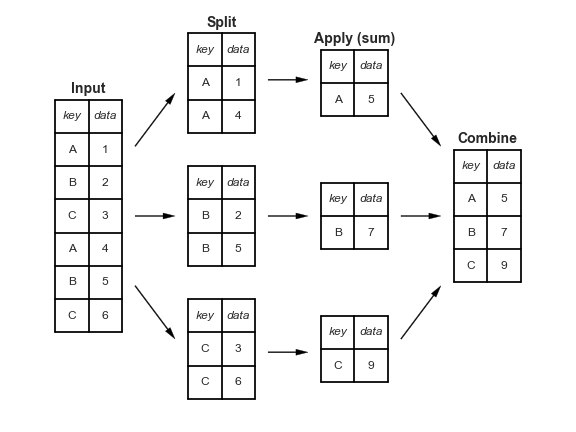


In [744]:
movies =  pd.read_csv("./imdb-top-1000.csv")
movies

,Series_Title,Released_Year,Runtime,Genre,IMDB_Rating,Director,Star1,No_of_Votes,Gross,Metascore
0,The Shawshank Redemption,1994,142,Drama,9.3,Frank Darabont,Tim Robbins,2343110,28341469.0,80.0
1,The Godfather,1972,175,Crime,9.2,Francis Ford Coppola,Marlon Brando,1620367,134966411.0,100.0
2,The Dark Knight,2008,152,Action,9.0,Christopher Nolan,Christian Bale,2303232,534858444.0,84.0
3,The Godfather: Part II,1974,202,Crime,9.0,Francis Ford Coppola,Al Pacino,1129952,57300000.0,90.0
4,12 Angry Men,1957,96,Crime,9.0,Sidney Lumet,Henry Fonda,689845,4360000.0,96.0
...,...,...,...,...,...,...,...,...,...,...
995,Breakfast at Tiffany's,1961,115,Comedy,7.6,Blake Edwards,Audrey Hepburn,166544,679874270.0,76.0
996,Giant,1956,201,Drama,7.6,George Stevens,Elizabeth Taylor,34075,195217415.0,84.0
997,From Here to Eternity,1953,118,Drama,7.6,Fred Zinnemann,Burt Lancaster,43374,30500000.0,85.0
998,Lifeboat,1944,97,Drama,7.6,Alfred Hitchcock,Tallulah Bankhead,26471,852142728.0,78.0


In [745]:
genres =  movies.groupby("Genre")  # Group the DataFrame by the "Genre" column and returns a gropby object. This object can be used to perform various operations on each group, such as aggregation, transformation, and filtering.

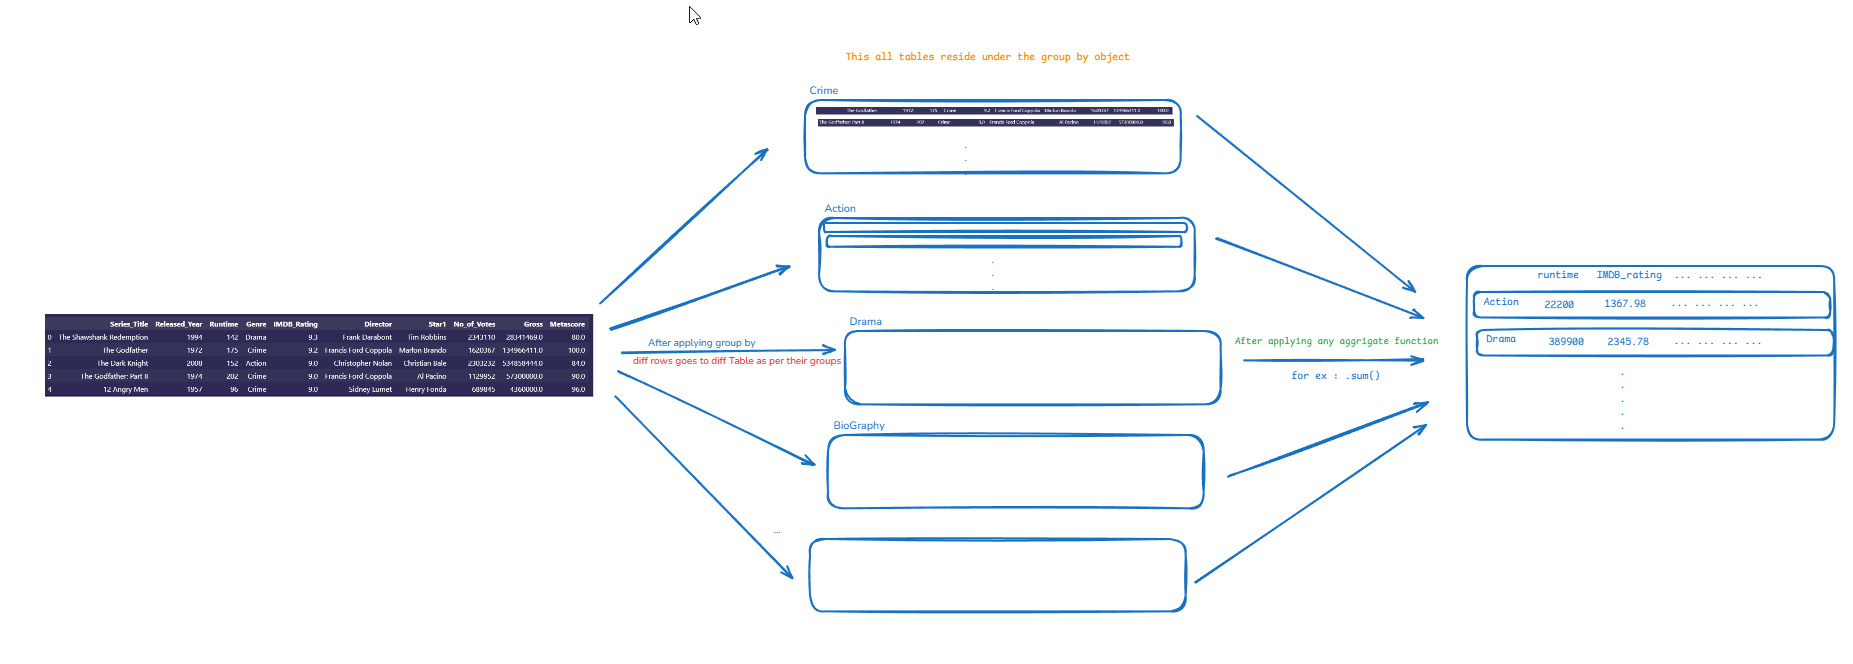

-  Groupby object is a dictionary-like object that contains key-value pairs, where the keys are the unique values of the grouping variable and the values are the corresponding groups of data.
- generes = { "Action" : [1,4,5] / movies_df_Action, "Comedy" : [2,3,6] / movies_df_Comedy, "Drama" : [7,8,9] / movies_df_Drama }  

In [746]:
genres.sum()[["Series_Title" , "Runtime"]] ##you can find that which genere is produced more movies in top 1000 imdb rated movies.

,Series_Title,Runtime
Genre,,
Action,The Dark KnightThe Lord of the Rings: The Retu...,22196
Adventure,InterstellarBack to the FutureInglourious Bast...,9656
Animation,Sen to Chihiro no kamikakushiThe Lion KingHota...,8166
Biography,Schindler's ListGoodfellasHamiltonThe Intoucha...,11970
Comedy,GisaengchungLa vita è bellaModern TimesCity Li...,17380
Crime,The GodfatherThe Godfather: Part II12 Angry Me...,13524
Drama,The Shawshank RedemptionFight ClubForrest Gump...,36049
Family,E.T. the Extra-TerrestrialWilly Wonka & the Ch...,215
Fantasy,Das Cabinet des Dr. CaligariNosferatu,170


In [747]:
genres.count()

,Series_Title,Released_Year,Runtime,IMDB_Rating,Director,Star1,No_of_Votes,Gross,Metascore
Genre,,,,,,,,,
Action,172,172,172,172,172,172,172,172,143
Adventure,72,72,72,72,72,72,72,72,64
Animation,82,82,82,82,82,82,82,82,75
Biography,88,88,88,88,88,88,88,88,79
Comedy,155,155,155,155,155,155,155,155,125
Crime,107,107,107,107,107,107,107,107,87
Drama,289,289,289,289,289,289,289,289,241
Family,2,2,2,2,2,2,2,2,2
Fantasy,2,2,2,2,2,2,2,2,0


In [748]:
# find the top 3 genres by total earning
movies.groupby('Genre').sum()['Gross'].sort_values(ascending=False).head(3) 

Genre
Drama     3.540997e+10
Action    3.263226e+10
Comedy    1.566387e+10
Name: Gross, dtype: float64

In [749]:
## find std for on the column for runtime for each genre
# movies.groupby("Genre").std() -- will throw an error as std is not defined for non-numeric data types. So we will select only the numeric columns before applying the std method.

movies.groupby("Genre")['Runtime'].std()

Genre
Action       28.500706
Adventure    33.317320
Animation    14.530471
Biography    25.514466
Comedy       22.946213
Crime        27.689231
Drama        27.740490
Family       10.606602
Fantasy      12.727922
Film-Noir     4.000000
Horror       13.604812
Mystery      14.475423
Thriller           NaN
Western      17.153717
Name: Runtime, dtype: float64

In [750]:
## agg = “apply one or more summary functions to grouped data”

genres["Runtime"].agg(['min', 'max', 'mean', 'sum']) # This applies multiple functions to each column for all columns.

,min,max,mean,sum
Genre,,,,
Action,45,321,129.046512,22196
Adventure,88,228,134.111111,9656
Animation,71,137,99.585366,8166
Biography,93,209,136.022727,11970
Comedy,68,188,112.129032,17380
Crime,80,229,126.392523,13524
Drama,64,242,124.737024,36049
Family,100,115,107.500000,215
Fantasy,76,94,85.000000,170


In [751]:
genres.agg({
    'Runtime': ['min', 'mean', 'max'],
    'Gross': 'sum',
    'IMDB_Rating': 'mean'
})  # This applies different functions to different explicit columns mentiond by us .

Runtime                          Gross IMDB_Rating
              min        mean  max           sum        mean
Genre                                                       
Action         45  129.046512  321  3.263226e+10    7.949419
Adventure      88  134.111111  228  9.496922e+09    7.937500
Animation      71   99.585366  137  1.463147e+10    7.930488
Biography      93  136.022727  209  8.276358e+09    7.938636
Comedy         68  112.129032  188  1.566387e+10    7.901290
Crime          80  126.392523  229  8.452632e+09    8.016822
Drama          64  124.737024  242  3.540997e+10    7.957439
Family        100  107.500000  115  4.391106e+08    7.800000
Fantasy        76   85.000000   94  7.827267e+08    8.000000
Film-Noir     100  104.000000  108  1.259105e+08    7.966667
Horror         71  102.090909  122  1.034649e+09    7.909091
Mystery        96  119.083333  138  1.256417e+09    7.975000
Thriller      108  108.000000  108  1.755074e+07    7.800000
Western       132  148.250000  165  5.822151e+07    8.350000

Apply Function

- **Apply on Series**  When you select a single column/Row (which is a Series) or create a standalone Series, .apply() operates element-wise. The function you pass receives individual data values, one at a time. Example : 
```python
         df['score'].apply(lambda x: x * 10)`  
```
-  In pandas, rows are signified with 0 (axis=0), while columns are signified with 1 (axis=1)
    - axis=0 (Rows / Index): Refers to the vertical direction or operations moving down the rows
    - axis=1 (Columns): Refers to the horizontal direction or operations moving across the columns

- **Apply on DataFrame**  When you call .apply() on an entire DataFrame, it processes data row-wise or column-wise. The function you pass receives a whole Series representing that entire row or column. DOCs [1](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.apply.html), [2](https://www.digitalocean.com/community/tutorials/pandas-dataframe-apply-examples)
    - • axis=0 (Default): Applies the function to each column (iterating down the rows). And function receives a Series representing each column and fuction apllied top to bottom in that column series.
    - • axis=1: Applies the function to each row (iterating across the columns).  And function receives a Series representing each row and function applied left to right in that row series.

- Example of using .apply() on a DataFrame:

```python
         # Finds the maximum value of each column (default is axis=0, which means column-wise)
         df.apply(lambda col: col.max(), axis=0) 

         # Adds values from Column_A and Column_B together for every row
         df.apply(lambda row: row['Column_A'] + row['Column_B'], axis=1)
```


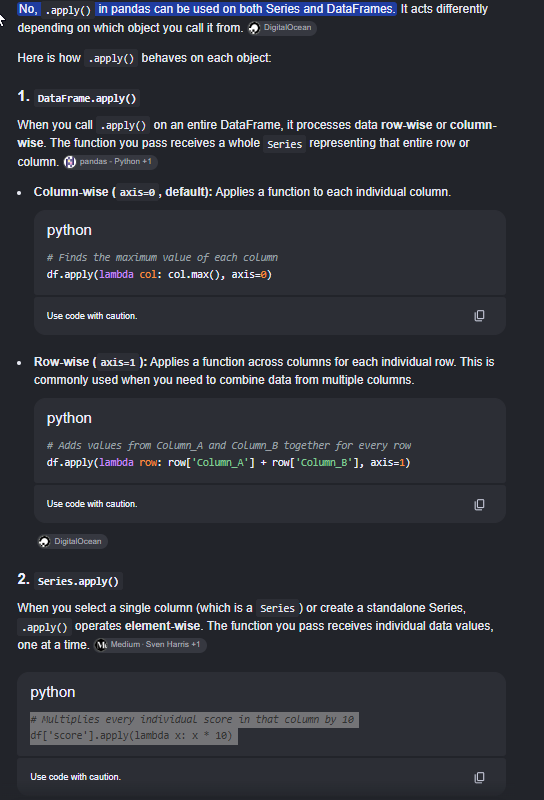

- GroupBy Attributes and Methods
    - `len(gropbyObject)` - Returns the number of groups in the GroupBy object.
    - `size()` - Returns a Series containing the size of each group.
    - `first()` / `last()` - Returns the first or last item in each group.
    - `get_group()` - Returns the group with the specified name.
    - `groups` - Returns a dictionary mapping group names to their corresponding data.
    - `describe()` - Generates descriptive statistics for each group.
    - `sample()` - Returns a random sample of items from each group.
    - `nunique()` - Returns the number of unique items in each group.


- Looping through Groups
    - You can iterate over the groups in a GroupBy object using a for loop.
    - Each iteration returns a tuple containing the group name and the corresponding DataFrame.

    

In [752]:

# find the higehst rated moie of each genre
df = pd.DataFrame(columns=movies.columns)
print(df)

print("________")

for genre, data in movies.groupby('Genre'):
    best_row = data.loc[data['IMDB_Rating'].idxmax()]
    df = pd.concat([df, best_row.to_frame().T], ignore_index=True)

df


Empty DataFrame
Columns: [Series_Title, Released_Year, Runtime, Genre, IMDB_Rating, Director, Star1, No_of_Votes, Gross, Metascore]
Index: []
________


,Series_Title,Released_Year,Runtime,Genre,IMDB_Rating,Director,Star1,No_of_Votes,Gross,Metascore
0,The Dark Knight,2008,152,Action,9.0,Christopher Nolan,Christian Bale,2303232,534858444.0,84.0
1,Interstellar,2014,169,Adventure,8.6,Christopher Nolan,Matthew McConaughey,1512360,188020017.0,74.0
2,Sen to Chihiro no kamikakushi,2001,125,Animation,8.6,Hayao Miyazaki,Daveigh Chase,651376,10055859.0,96.0
3,Schindler's List,1993,195,Biography,8.9,Steven Spielberg,Liam Neeson,1213505,96898818.0,94.0
4,Gisaengchung,2019,132,Comedy,8.6,Bong Joon Ho,Kang-ho Song,552778,53367844.0,96.0
5,The Godfather,1972,175,Crime,9.2,Francis Ford Coppola,Marlon Brando,1620367,134966411.0,100.0
6,The Shawshank Redemption,1994,142,Drama,9.3,Frank Darabont,Tim Robbins,2343110,28341469.0,80.0
7,E.T. the Extra-Terrestrial,1982,115,Family,7.8,Steven Spielberg,Henry Thomas,372490,435110554.0,91.0
8,Das Cabinet des Dr. Caligari,1920,76,Fantasy,8.1,Robert Wiene,Werner Krauss,57428,337574718.0,NaN
9,The Third Man,1949,104,Film-Noir,8.1,Carol Reed,Orson Welles,158731,449191.0,97.0


#### Plotting Graphs 


<Axes: >

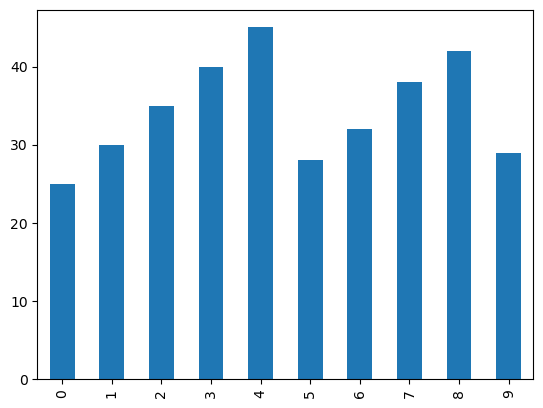

In [753]:
student_df["age"].plot(kind = "bar")

In [754]:
student_df["marks"]

0    85
1    92
2    78
3    96
4    88
5    90
6    95
7    80
8    85
9    92
Name: marks, dtype: int64

<Axes: title={'center': 'Total Runtime by Genre'}, xlabel='Genre', ylabel='Total Runtime'>

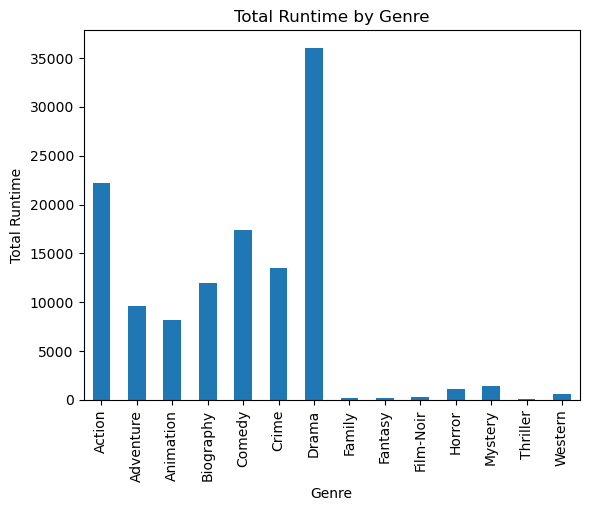

In [755]:
genres["Runtime"].sum().plot(kind = "bar" , title = "Total Runtime by Genre", xlabel = "Genre", ylabel = "Total Runtime" )

<Axes: ylabel='IMDB_Rating'>

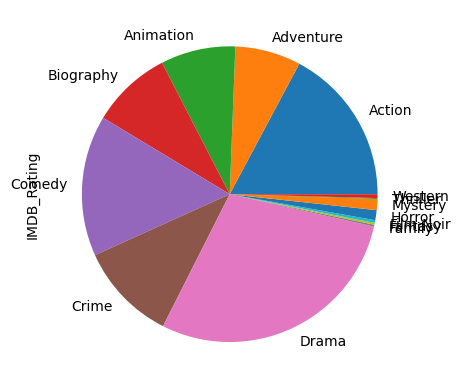

In [756]:
genres["IMDB_Rating"].sum().plot(kind = "pie")

<Axes: title={'center': 'Runtime Frequency Distribution for Drama Genre'}, xlabel='Runtime', ylabel='Frequency'>

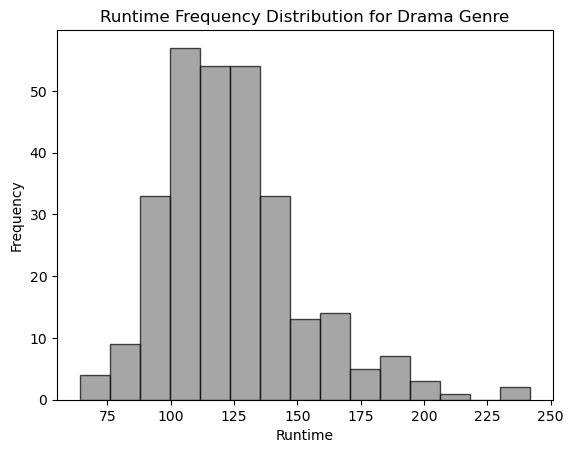

In [757]:
# runtime frequency distribution for each Drama genre

genres.get_group("Drama").Runtime.plot(kind = "hist" , title = "Runtime Frequency Distribution for Drama Genre", xlabel = "Runtime", ylabel = "Frequency" , bins = 15 , color = "gray" , edgecolor = "black" , alpha = 0.7)

<Axes: title={'center': 'Runtime Frequency Distribution for Drama Genre'}, xlabel='Runtime', ylabel='Frequency'>

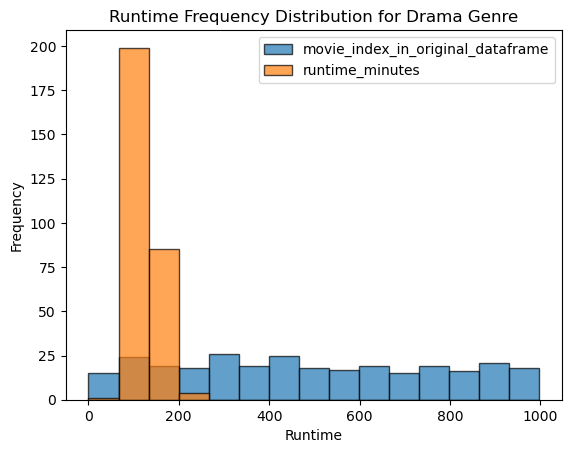

In [774]:
df_1 = genres.get_group("Drama")["Runtime"].reset_index()
df_1 = df_1.rename(columns={
    "Runtime": "runtime_minutes",
    "index": "movie_index_in_original_dataframe"
})
df_1
df_1.plot(kind = "hist" , title = "Runtime Frequency Distribution for Drama Genre", xlabel = "Runtime", ylabel = "Frequency" , bins = 15 ,  edgecolor = "black" , alpha = 0.7)

<Axes: title={'center': 'Scatter plot of Runtime for Drama Genre'}, xlabel='Movie Index in Original DataFrame', ylabel='Runtime (minutes)'>

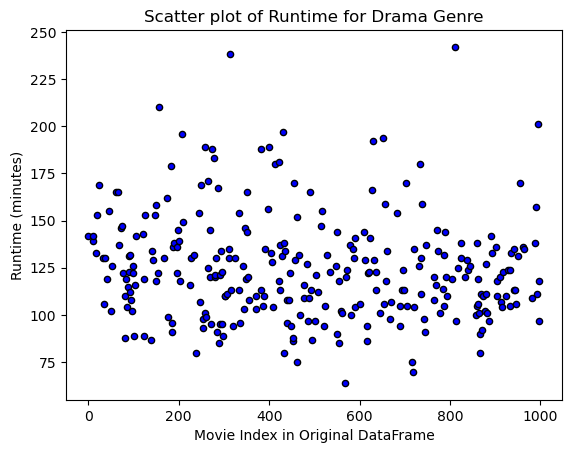

In [781]:
df_1.plot(kind = "scatter" , x = "movie_index_in_original_dataframe" , y = "runtime_minutes" , title = "Scatter plot of Runtime for Drama Genre", xlabel = "Movie Index in Original DataFrame", ylabel = "Runtime (minutes)" , color = "blue" , edgecolor = "black" , alpha = 0.7)

In [780]:
mean_line  = df_1["runtime_minutes"].mean()
mediadn_line = df_1["runtime_minutes"].median()
mode_line = df_1["runtime_minutes"].mode().values[0]
print("Mean of runtime for Drama genre: ", mean_line)
print("Median of runtime for Drama genre: ", mediadn_line)
print("Mode of runtime for Drama genre: ", mode_line)

Mean of runtime for Drama genre:  124.73702422145328
Median of runtime for Drama genre:  121.0
Mode of runtime for Drama genre:  113


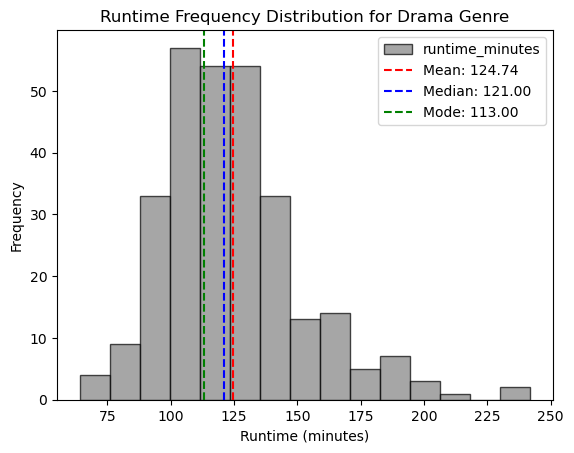

In [782]:
import matplotlib.pyplot as plt

runtime = df_1["runtime_minutes"]

mean_line = runtime.mean()
median_line = runtime.median()
mode_line = runtime.mode().iloc[0]

ax = runtime.plot(
    kind="hist",
    bins=15,
    title="Runtime Frequency Distribution for Drama Genre",
    xlabel="Runtime (minutes)",
    ylabel="Frequency",
    color="gray",
    edgecolor="black",
    alpha=0.7
)

ax.axvline(mean_line, color="red", linestyle="--", label=f"Mean: {mean_line:.2f}")
ax.axvline(median_line, color="blue", linestyle="--", label=f"Median: {median_line:.2f}")
ax.axvline(mode_line, color="green", linestyle="--", label=f"Mode: {mode_line:.2f}")

ax.legend()
plt.show()